In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path
from datetime import timedelta, timezone

src_path = Path().resolve().parents[1] / 'src'
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))


from sciezka_projektu import get_project_root

PROJECT_ROOT = get_project_root()

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "final"

df_r_pz1 = pd.read_parquet(DATA_PATH / "godzinowe-pz1-final.parquet")


,przepompowano_m3,energia_kwh,opad_mm
Data_czas,,,
2024-03-19 16:00:00+01:00,217.5,16.585,0.0
2024-03-19 17:00:00+01:00,132.8,14.188,0.0
2024-03-19 18:00:00+01:00,167.2,8.675,0.0
2024-03-19 19:00:00+01:00,127.3,11.805,0.0
2024-03-19 20:00:00+01:00,124.4,9.104,0.0
...,...,...,...
2026-09-29 09:00:00+01:00,175.7,NaN,0.0
2026-09-29 10:00:00+01:00,200.5,NaN,0.0
2026-09-29 11:00:00+01:00,135.6,NaN,0.0


,ilosc
Data_czas,
2024-03-19 16:00:00+01:00,0.0
2024-03-19 17:00:00+01:00,0.0
2024-03-19 18:00:00+01:00,0.0
2024-03-19 19:00:00+01:00,0.0
2024-03-19 20:00:00+01:00,0.0
...,...
2026-09-29 09:00:00+01:00,0.0
2026-09-29 10:00:00+01:00,0.0
2026-09-29 11:00:00+01:00,0.0


In [55]:
%load_ext autoreload
%autoreload 2

from models.final.przepompowanie_rybnik_dane import przygotuj_dane_przepompowanie

X_pz1,y_pz1, X_pnb1, y_pnb1 = przygotuj_dane_przepompowanie()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [56]:
%load_ext autoreload
%autoreload 2
X = X_pz1
y = y_pz1

train_end = int(len(X) * 0.7)

X_train = X.iloc[:train_end]
X_test = X.iloc[train_end:]

y_train = y.iloc[:train_end]
y_test = y.iloc[train_end:]

#print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
#print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
#print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [57]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_test)
q_val = cb_q97.predict(X_test)

Godziny ponad normę: 70 z 4003


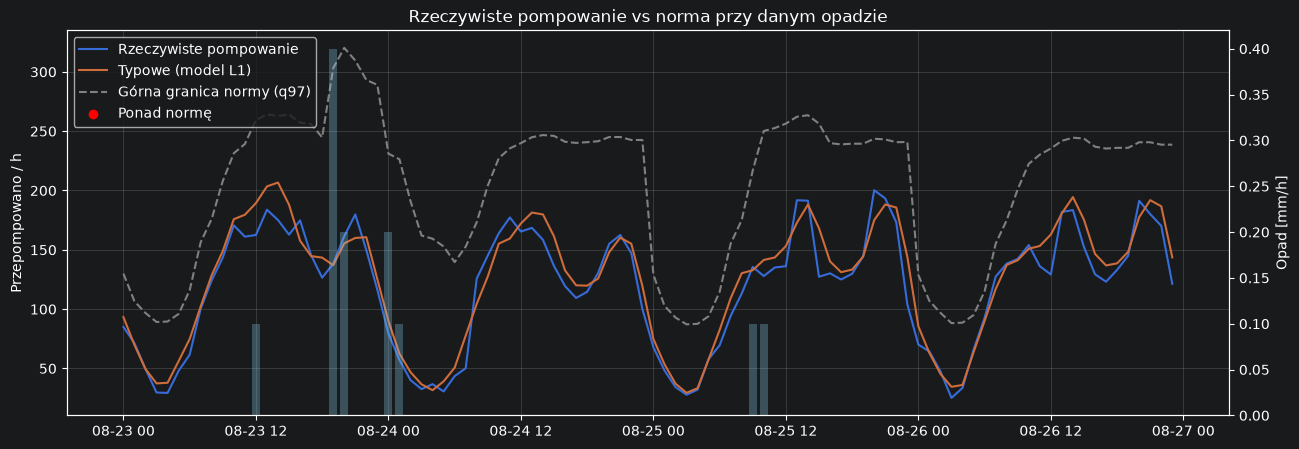

In [59]:
results_val = pd.DataFrame({
    "rzeczywiste": y_test,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_test["opad_0h"],
    "opad_6h": X_test["opad_6h"],
}, index=y_test.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2025-08-23":"2025-08-26"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [48]:
# Alarm, gdy rzeczywiste pompowanie przekracza Q97
results_val["alarm"] = results_val["anomaly"]

# Nadwyżka względem typowej prognozy pogodowej
results_val["nadwyzka"] = (
    results_val["rzeczywiste"] - results_val["prognoza"]
).clip(lower=0)

print("Liczba godzin alarmowych:", results_val["alarm"].sum())

print(
    "Suma nadwyżek w godzinach alarmowych:",
    round(results_val.loc[results_val["alarm"], "nadwyzka"].sum(), 2)
)

Liczba godzin alarmowych: 70
Suma nadwyżek w godzinach alarmowych: 10482.76


In [49]:
anomalie = results_val[results_val["alarm"]].copy()

#kiedy wystąpiły alarmy, jaka była nadwyżka i czy padało
display(anomalie[["rzeczywiste", "prognoza", "q97", "nadwyzka", "ponad_q97", "opad", "opad_6h"]])

,rzeczywiste,prognoza,q97,nadwyzka,ponad_q97,opad,opad_6h
Data_czas,,,,,,,
2025-04-18 16:00:00+01:00,274.7,157.350292,248.425980,117.349708,26.274020,0.1,0.3
2025-04-25 14:00:00+01:00,440.8,222.895712,337.793727,217.904288,103.006273,0.3,2.7
2025-05-22 22:00:00+01:00,457.4,306.900669,393.715895,150.499331,63.684105,2.0,9.3
2025-05-26 15:00:00+01:00,340.8,185.708449,328.135201,155.091551,12.664799,0.0,1.1
2025-05-26 16:00:00+01:00,303.1,154.135237,300.549072,148.964763,2.550928,0.0,1.1
...,...,...,...,...,...,...,...
2025-09-16 03:00:00+01:00,345.9,275.471223,324.644244,70.428777,21.255756,1.7,15.7
2025-09-16 08:00:00+01:00,152.5,212.668144,122.095553,0.000000,30.404447,0.0,3.6
2025-09-17 02:00:00+01:00,52.5,48.882937,51.555657,3.617063,0.944343,0.0,0.0


In [50]:
from sklearn.metrics import mean_absolute_error
# Ewaluacja na zbiorze testowym
y_pred_test = cb_median.predict(X_test)
q_test = cb_q97.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
odsetek_test = (y_test > q_test).mean() * 100

print("MAE TEST:", round(mae_test, 2))
prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")
print("Liczba alarmów TEST:", int((y_test > q_test).sum()))


MAE TEST: 25.74
MAE baseline: 24.51
Przekroczenia Q97 TEST: 1.75 %
Liczba alarmów TEST: 70


In [42]:
#SHAP
from SHAP import generate_shap_from_tree

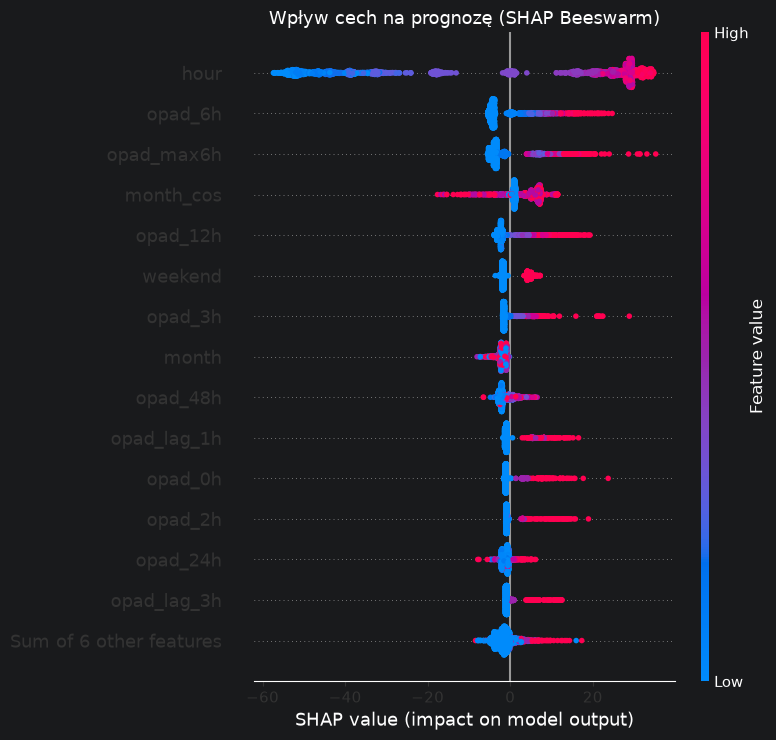

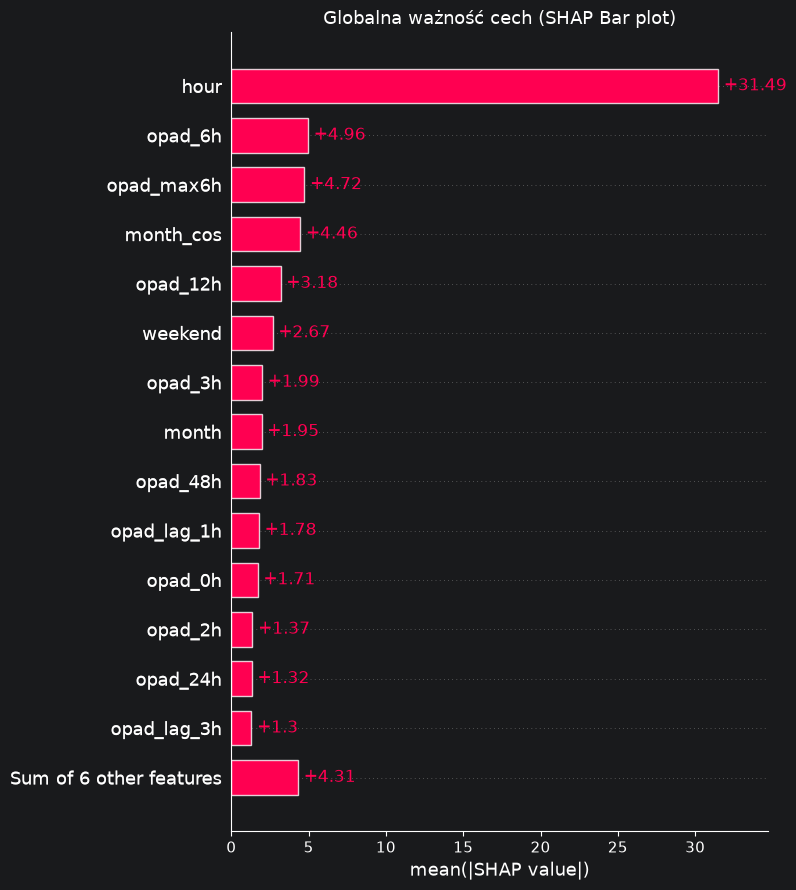

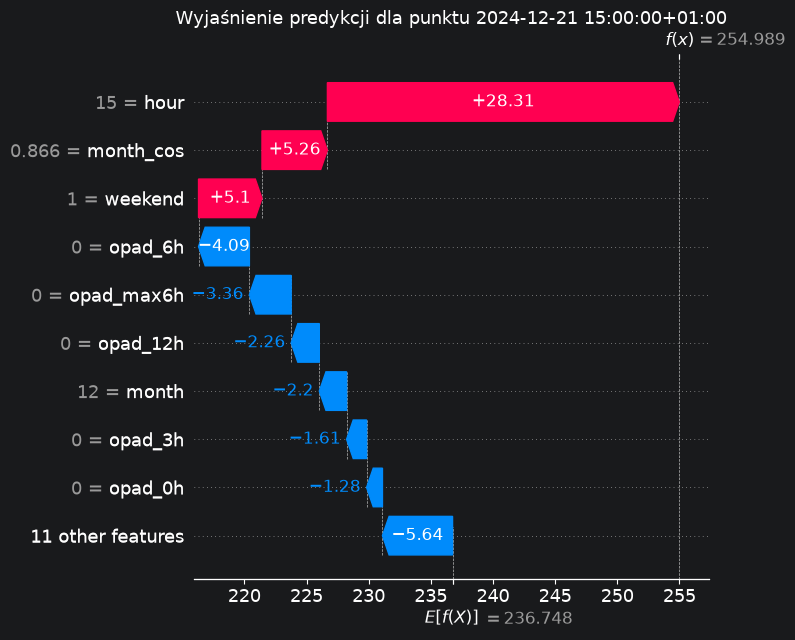

In [43]:
generate_shap_from_tree(cb_q97,X_test,date_with_time="2024-12-21 15:00:00")

# OPTYMALIZACJA OPTUNA

In [51]:

import optuna

train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

import numpy as np
import optuna


# STROJENIE MODELU MEDIANOWEGO (cb_median)
def objective_median(trial):
    params = {
        'loss_function': 'MAE',
        'eval_metric': 'MAE',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    preds = model.predict(X_val)
    mae = np.mean(np.abs(y_val - preds))
    return mae

study_median = optuna.create_study(direction="minimize")
study_median.optimize(objective_median, n_trials=40)
print("Najlepsze parametry dla Median:", study_median.best_params)


# STROJENIE MODELU KWANTYLOWEGO (cb_q97)
def pinball_loss(y_true, y_pred, alpha=0.97):
    err = y_true - y_pred
    return np.mean(np.maximum(alpha * err, (alpha - 1.0) * err))

def objective_q97(trial):
    params = {
        'loss_function': 'Quantile:alpha=0.97',
        'eval_metric': 'Quantile:alpha=0.97',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    q_preds = model.predict(X_val)

    #Błąd Pinball
    loss = pinball_loss(y_val, q_preds, alpha=0.97)

    #Kara za uciekanie od Coverage = 97%
    empirical_coverage = np.mean(y_val <= q_preds)
    coverage_penalty = np.abs(empirical_coverage - 0.97) * 5.0

    return loss + coverage_penalty

study_q97 = optuna.create_study(direction="minimize")
study_q97.optimize(objective_q97, n_trials=40)
print("Najlepsze parametry dla Q97:", study_q97.best_params)

C:\Users\tprze\Desktop\Smart_Water_Challenge_2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-28 12:56:15,660] A new study created in memory with name: no-name-a07d4afe-599d-439d-8608-bc0a688b4d0c
[I 2026-10-28 12:56:16,184] Trial 0 finished with value: 23.013578783477087 and parameters: {'learning_rate': 0.04830947461464489, 'depth': 4, 'l2_leaf_reg': 12.891166119288734, 'random_strength': 1.4012305023058074}. Best is trial 0 with value: 23.013578783477087.
[I 2026-10-28 12:56:17,539] Trial 1 finished with value: 22.67988673353259 and parameters: {'learning_rate': 0.013256582020968874, 'depth': 8, 'l2_leaf_reg': 14.476448680100976, 'random_strength': 0.05432782615140127}. Best is trial 1 with value: 22.67988673353259.
[I 2026-10-28 12:56:19,030] Trial 2 finished with value: 23.129082778091558

Najlepsze parametry dla Median: {'learning_rate': 0.04271266638606637, 'depth': 8, 'l2_leaf_reg': 13.921831722230372, 'random_strength': 0.7055558479227513}


[I 2026-10-28 12:57:06,899] Trial 0 finished with value: 3.481375485778811 and parameters: {'learning_rate': 0.026774888133916167, 'depth': 6, 'l2_leaf_reg': 14.018659520062988, 'random_strength': 4.131547717974275}. Best is trial 0 with value: 3.481375485778811.
[I 2026-10-28 12:57:09,725] Trial 1 finished with value: 3.621097060776736 and parameters: {'learning_rate': 0.028330303067233244, 'depth': 6, 'l2_leaf_reg': 5.4173229674619705, 'random_strength': 2.5827886075134865}. Best is trial 0 with value: 3.481375485778811.
[I 2026-10-28 12:57:11,408] Trial 2 finished with value: 3.565041683902722 and parameters: {'learning_rate': 0.07771234857398715, 'depth': 8, 'l2_leaf_reg': 3.574505988822804, 'random_strength': 4.715644542433353}. Best is trial 0 with value: 3.481375485778811.
[I 2026-10-28 12:57:18,930] Trial 3 finished with value: 3.554211977362452 and parameters: {'learning_rate': 0.017663764115734202, 'depth': 7, 'l2_leaf_reg': 5.206713082417923, 'random_strength': 2.30827916169

Najlepsze parametry dla Q97: {'learning_rate': 0.026774888133916167, 'depth': 6, 'l2_leaf_reg': 14.018659520062988, 'random_strength': 4.131547717974275}


In [52]:
print("Najlepszy wynik median (MAE):", study_median.best_value)
print("Najlepsze parametry median:", study_median.best_params)

print("Najlepszy wynik q97 (MAE):", study_q97.best_value)
print("Najlepsze parametry q97:", study_q97.best_params)

Najlepszy wynik median (MAE): 22.136084865066994
Najlepsze parametry median: {'learning_rate': 0.04271266638606637, 'depth': 8, 'l2_leaf_reg': 13.921831722230372, 'random_strength': 0.7055558479227513}
Najlepszy wynik q97 (MAE): 3.481375485778811
Najlepsze parametry q97: {'learning_rate': 0.026774888133916167, 'depth': 6, 'l2_leaf_reg': 14.018659520062988, 'random_strength': 4.131547717974275}


In [53]:
# CATBOOST
from catboost import CatBoostRegressor


check_median = CatBoostRegressor(
    **study_median.best_params,
    loss_function="MAE",
    eval_metric="MAE",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=100
)
check_median.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True
)


best_trees = check_median.get_best_iteration()
print(f"Optymalna liczba iteracji: {best_trees}")

0:	learn: 48.7065851	test: 42.6631568	best: 42.6631568 (0)	total: 2.73ms	remaining: 6.83s
100:	learn: 20.4298456	test: 22.1547571	best: 22.1402887 (98)	total: 405ms	remaining: 9.62s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 22.13608381
bestIteration = 107

Shrink model to first 108 iterations.
Optymalna liczba iteracji: 107


In [54]:
from catboost import CatBoostRegressor


check_q97 = CatBoostRegressor(
    **study_q97.best_params,
    loss_function="Quantile:alpha=0.97",
    eval_metric="Quantile:alpha=0.97",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=0
)

check_q97.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True)

best_trees_q97 = check_q97.get_best_iteration()
q_test = check_q97.predict(X_test)
print(f"Optymalna liczba iteracji dla q97 to: {best_trees_q97}")
odsetek_test = np.mean(y_test.to_numpy() > q_test.ravel()) * 100

print("MAE TEST:", round(mae_test, 2))
prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")

Optymalna liczba iteracji dla q97 to: 1303
MAE TEST: 25.74
MAE baseline: 26.26
Przekroczenia Q97 TEST: 2.5 %
